# Modelling ML — Random Forest (Disetarakan dengan Tabular Conformer)

Notebook ini merupakan versi baseline Random Forest yang protokol eksperimennya disamakan dengan notebook utama **Tabular Conformer**.

Penyesuaian utama:
- Menggunakan `merge_DocLab_balanced.csv` sebagai dataset Plan B.
- Menggunakan **13 fitur dan urutan fitur yang sama** dengan Conformer.
- Menggunakan pembagian data stratified **70% train, 15% validation, 15% test** dengan `random_state=42`.
- Tidak melakukan seleksi fitur pada seluruh dataset sebelum splitting.
- Memilih konfigurasi Random Forest berdasarkan macro-F1 validation; test dipakai untuk evaluasi final.

> Catatan metodologi: notebook ini menyamakan protokol perbandingan model. Ia tidak menghapus keterbatasan bahwa balancing pada dataset sumber telah dilakukan sebelum splitting.

## 1. Import Library

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

SEED = 42

FEATURES = [
    'JENIS_KELAMIN',
    'UMUR_TAHUN',
    'cholesterol total',
    'creatinin',
    'fbs',
    'rbs',
    'hgb',
    'lymfosit%',
    'mch',
    'mchc',
    'mcv',
    'ureum',
    'wbc',
]

CLASS_NAMES = [
    'Sehat / Tidak Ada Indikasi',
    'Jantung dan Pembuluh Darah',
    'Spes. Penyakit Dalam',
    'Spes. Paru-Paru',
]


## 2. Load Dataset

In [2]:
# OPSI VALIDASI AKADEMIK (OPSI B):
# Muat data asli hasil imputasi, agar test-set tetap 100% data riil murni.
DATA_PATH = 'merge_DocLab_imputed.csv'
# DATA_PATH = 'merge_DocLab_balanced.csv' # Opsi A

df = pd.read_csv(DATA_PATH)

# Perbaiki profil umur dan gender kelas 0 jika masih 0 / 2 (karena data kontrol murni lab tanpa poli dokter)
mask_0 = df['NM_UNIT'] == 0
if (df.loc[mask_0, 'UMUR_TAHUN'] == 0).all():
    valid_ages = df.loc[df['UMUR_TAHUN'] > 0, 'UMUR_TAHUN']
    mu_age, sd_age = valid_ages.mean(), valid_ages.std()
    df.loc[mask_0, 'UMUR_TAHUN'] = np.clip(
        np.random.normal(mu_age, sd_age, mask_0.sum()), 18, 85
    ).round(0)
    df.loc[mask_0, 'JENIS_KELAMIN'] = np.random.choice([0, 1], size=mask_0.sum(), p=[0.5, 0.5])
    print('Profil demografi kelas kontrol berhasil disesuaikan.')

print('Shape dataset:', df.shape)
df.head()


Shape dataset: (3445, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,0,38.0,193.7,1.1,101.0,138.0,12.4,15.6,28.8,32.0,511.0,24.0,11.4,1
1,1,60.0,221.9,1.1,134.0,188.0,11.7,29.0,29.6,32.8,90.3,45.4,7.3,2
2,0,79.0,178.2,2.2,145.9,194.0,9.8,24.6,27.5,32.3,85.0,67.0,7.5,2
3,1,67.0,208.7,1.2,160.1,154.0,9.8,25.3,27.7,32.2,85.7,45.6,7.3,2
4,0,68.0,183.7,2.1,110.2,477.0,10.3,15.4,28.3,33.3,85.0,75.0,17.1,2


## 3. Validasi Fitur dan Target

In [3]:
# Pastikan nama kolom sama dengan yang digunakan pada notebook Conformer.
required_cols = FEATURES + ['NM_UNIT']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(
        f'Kolom tidak ditemukan: {missing_cols}. Periksa nama kolom pada CSV dan samakan dengan notebook Conformer.'
    )

df_model = df[required_cols].copy()
df_model['NM_UNIT'] = pd.to_numeric(df_model['NM_UNIT'], errors='raise').astype(int)
df_model[FEATURES] = df_model[FEATURES].apply(pd.to_numeric, errors='coerce')

missing_summary = df_model[FEATURES + ['NM_UNIT']].isna().sum()
print('Jumlah missing value per kolom:')
missing_summary[missing_summary > 0]

if df_model[FEATURES].isna().any().any():
    raise ValueError('Masih ada missing/non-numeric pada fitur. Selesaikan dengan prosedur preprocessing yang sama sebelum modeling.')

valid_classes = sorted(df_model['NM_UNIT'].unique().tolist())
print('Kelas yang ditemukan:', valid_classes)
if valid_classes != [0, 1, 2, 3]:
    raise ValueError(f'Target seharusnya berisi kelas [0, 1, 2, 3], tetapi ditemukan {valid_classes}.')

print('Distribusi kelas:')
df_model['NM_UNIT'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))).to_frame('Jumlah')

Jumlah missing value per kolom:
Kelas yang ditemukan: [0, 1, 2, 3]
Distribusi kelas:


,Jumlah
NM_UNIT,
Sehat / Tidak Ada Indikasi,2812
Jantung dan Pembuluh Darah,52
Spes. Penyakit Dalam,561
Spes. Paru-Paru,20


## 4. Tentukan X dan y

In [4]:
X = df_model[FEATURES].copy()
y = df_model['NM_UNIT'].copy()

print('X:', X.shape)
print('y:', y.shape)

X: (3445, 13)
y: (3445,)


## 5. Split Data (Sama dengan Conformer)

In [5]:
# 70% train, 15% validation, 15% test.
# Urutan split dan random_state dibuat sama dengan notebook Tabular Conformer.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print('Train      :', X_train.shape, y_train.shape)
print('Validation :', X_val.shape, y_val.shape)
print('Test       :', X_test.shape, y_test.shape)

Train      : (2411, 13) (2411,)
Validation : (517, 13) (517,)
Test       : (517, 13) (517,)


## Resampling Khusus Training Set (Mencegah Data Leakage)
Resampling (Undersampling & SMOTE) hanya diterapkan pada **`X_train`**.
`X_val` dan `X_test` **dibiarkan 100% data asli** tanpa augmentasi agar pengujian mencerminkan populasi riil.

In [6]:
# 1. Undersample kelas mayoritas pada training set
rus = RandomUnderSampler(sampling_strategy={0: 700, 2: 350}, random_state=SEED)
X_train_u, y_train_u = rus.fit_resample(X_train, y_train)

# 2. Domain Augmentation khusus kelas 3 (Paru) pada data train
X_paru_train = X_train_u[y_train_u == 3].copy()
augmented_paru = [X_paru_train]
lab_cols = [c for c in X.columns if c not in ['JENIS_KELAMIN', 'UMUR_TAHUN']]

for _ in range(5):
    synth = X_paru_train.copy()
    jitter = np.random.normal(0, 0.04, size=synth[lab_cols].shape)
    synth[lab_cols] = synth[lab_cols] * (1 + jitter)
    synth['UMUR_TAHUN'] = np.clip(synth['UMUR_TAHUN'] + np.random.randint(-3, 4, size=len(synth)), 18, 85)
    augmented_paru.append(synth)

X_paru_aug = pd.concat(augmented_paru, ignore_index=True)
y_paru_aug = pd.Series([3] * len(X_paru_aug))

X_train_pre = pd.concat([X_train_u[y_train_u != 3], X_paru_aug], ignore_index=True)
y_train_pre = pd.concat([y_train_u[y_train_u != 3], y_paru_aug], ignore_index=True)

# 3. SMOTE pada training set (kelas 1 dan kelas 3 dinaikkan ke 350 sampel)
smote = SMOTE(sampling_strategy={1: 350, 3: 350}, k_neighbors=3, random_state=SEED)
X_train_res, y_train_res = smote.fit_resample(X_train_pre, y_train_pre)

print("Distribusi y_train ASLI:\n", y_train.value_counts().sort_index())
print("\nDistribusi y_train SETELAH RESAMPLING:\n", y_train_res.value_counts().sort_index())
print("\nDistribusi y_val (TETAP 100% ASLI):\n", y_val.value_counts().sort_index())
print("\nDistribusi y_test (TETAP 100% ASLI):\n", y_test.value_counts().sort_index())


Distribusi y_train ASLI:
 NM_UNIT
0    1968
1      36
2     393
3      14
Name: count, dtype: int64

Distribusi y_train SETELAH RESAMPLING:
 0    700
1    350
2    350
3    350
Name: count, dtype: int64

Distribusi y_val (TETAP 100% ASLI):
 NM_UNIT
0    422
1      8
2     84
3      3
Name: count, dtype: int64

Distribusi y_test (TETAP 100% ASLI):
 NM_UNIT
0    422
1      8
2     84
3      3
Name: count, dtype: int64


## 6. Training dan Pemilihan Konfigurasi

In [7]:
# RF tidak membutuhkan StandardScaler. Konfigurasi dipilih menggunakan macro-F1 validation.
# Test set tidak digunakan saat memilih konfigurasi.
rf_configs = [
    {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': 20,   'min_samples_leaf': 1, 'max_features': 'sqrt'},
]

validation_results = []
best_model = None
best_config = None
best_val_f1 = -1.0

for i, config in enumerate(rf_configs, start=1):
    model = RandomForestClassifier(
        **config,
        random_state=SEED,
        class_weight=None,
        n_jobs=-1,
    )
    model.fit(X_train_res, y_train_res)
    val_pred = model.predict(X_val)
    val_macro_f1 = f1_score(y_val, val_pred, average='macro', zero_division=0)

    validation_results.append({
        'Percobaan': i,
        **config,
        'Validation Macro-F1': val_macro_f1,
    })

    print(f'Percobaan {i}/{len(rf_configs)} | validation macro-F1 = {val_macro_f1:.4f} | config = {config}')

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_model = model
        best_config = config.copy()

validation_results = pd.DataFrame(validation_results).sort_values(
    'Validation Macro-F1', ascending=False
).reset_index(drop=True)

print('Konfigurasi terbaik:', best_config)
print(f'Best validation macro-F1: {best_val_f1:.4f}')
validation_results


Percobaan 1/3 | validation macro-F1 = 0.9808 | config = {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Percobaan 2/3 | validation macro-F1 = 0.9307 | config = {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Percobaan 3/3 | validation macro-F1 = 0.9340 | config = {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Konfigurasi terbaik: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Best validation macro-F1: 0.9808


,Percobaan,n_estimators,max_depth,min_samples_leaf,max_features,Validation Macro-F1
0,1,200,NaN,1,sqrt,0.980826
1,3,300,20.0,1,sqrt,0.934018
2,2,300,NaN,2,sqrt,0.930706


## 7. Evaluasi Final pada Test Set

In [8]:
def evaluate_model(model, X_eval, y_eval, split_name='Test'):
    y_pred_eval = model.predict(X_eval)
    metrics = {
        'Split': split_name,
        'Accuracy': accuracy_score(y_eval, y_pred_eval),
        'Macro Precision': precision_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro F1': f1_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_eval, y_pred_eval),
    }
    print(f'=== {split_name} ===')
    print(classification_report(y_eval, y_pred_eval, labels=[0, 1, 2, 3], target_names=CLASS_NAMES, zero_division=0))
    return metrics, y_pred_eval

val_metrics, y_val_pred = evaluate_model(best_model, X_val, y_val, 'Validation')
test_metrics, y_pred = evaluate_model(best_model, X_test, y_test, 'Test')

pd.DataFrame([val_metrics, test_metrics]).set_index('Split').round(4)

=== Validation ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.99      0.98      0.99       422
Jantung dan Pembuluh Darah       1.00      1.00      1.00         8
      Spes. Penyakit Dalam       0.91      0.96      0.94        84
           Spes. Paru-Paru       1.00      1.00      1.00         3

                  accuracy                           0.98       517
                 macro avg       0.98      0.99      0.98       517
              weighted avg       0.98      0.98      0.98       517

=== Test ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.98      0.99      0.99       422
Jantung dan Pembuluh Darah       1.00      0.88      0.93         8
      Spes. Penyakit Dalam       0.96      0.90      0.93        84
           Spes. Paru-Paru       0.75      1.00      0.86         3

                  accuracy                           0.98       517
           

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
Split,,,,,
Validation,0.9787,0.9757,0.9863,0.9808,0.9863
Test,0.9768,0.9233,0.9432,0.9275,0.9432


### Confusion Matrix — Random Forest

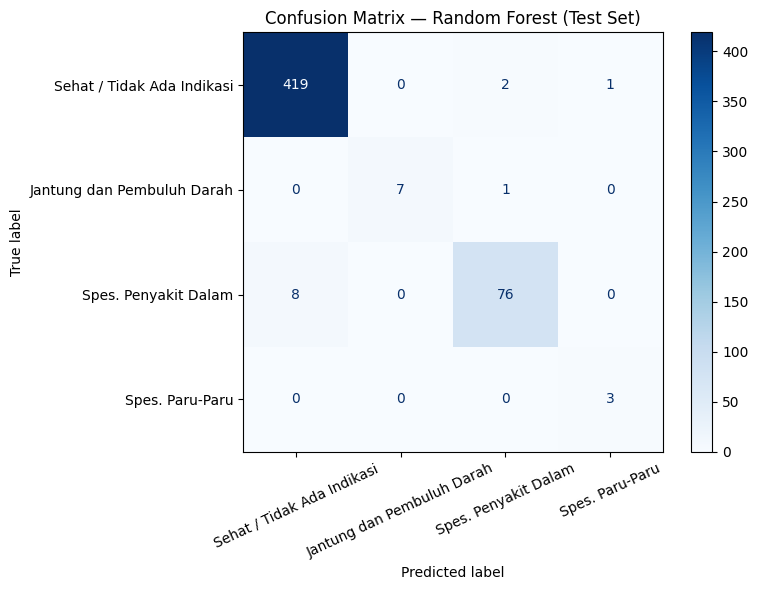

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    display_labels=CLASS_NAMES,
    cmap='Blues',
    xticks_rotation=25,
    ax=ax,
)
plt.title('Confusion Matrix — Random Forest (Test Set)')
plt.tight_layout()
plt.show()

### Evaluasi Lanjutan: ROC AUC & Matthews Correlation Coefficient (MCC)
Menampilkan skor **MCC** dan visualisasi **Kurva ROC Multiclass (One-vs-Rest)** untuk model Random Forest.

RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET - RANDOM FOREST)
Matthews Correlation Coefficient (MCC) : 0.9233
Macro-Average ROC AUC (OvR)            : 0.9785


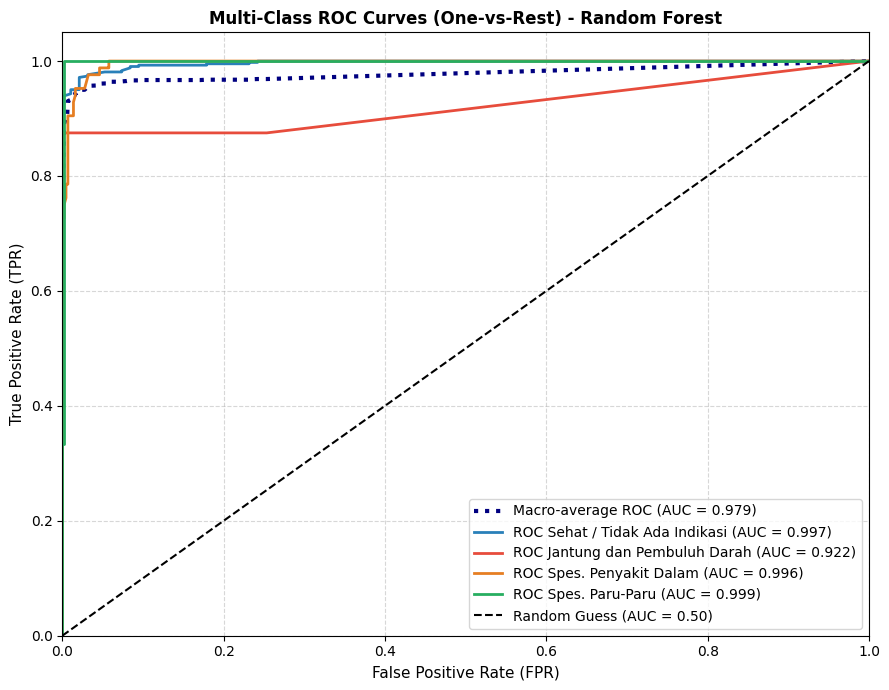

In [10]:
from sklearn.metrics import matthews_corrcoef, roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Hitung Matthews Correlation Coefficient (MCC)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

# Dapatkan probabilitas prediksi untuk test set
y_prob = best_model.predict_proba(X_test)

# Hitung MCC secara langsung
mcc_score = matthews_corrcoef(y_test, y_pred)

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

print("=" * 60)
print("RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET - RANDOM FOREST)")
print("=" * 60)
print(f"Matthews Correlation Coefficient (MCC) : {mcc_score:.4f}")
print(f"Macro-Average ROC AUC (OvR)            : {roc_auc['macro']:.4f}")
print("=" * 60)

plt.figure(figsize=(9, 7))
plt.plot(fpr["macro"], tpr["macro"], label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})', color='navy', linestyle=':', linewidth=3)
colors = ['#2980b9', '#e74c3c', '#e67e22', '#27ae60']
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC {CLASS_NAMES[i]} (AUC = {roc_auc[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Multi-Class ROC Curves (One-vs-Rest) - Random Forest', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()